# E-commerce Sales Analysis

**Dataset:** 10,000 synthetic e-commerce orders (practice dataset)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Goal:** Clean the data, find what drives revenue and returns, and turn charts into business insights.

In [5]:
import numpy as np
import pandas as pd

In [6]:
from google.colab import files
uploaded=files.upload()

Saving ecommerce_orders_10k.csv to ecommerce_orders_10k.csv


In [8]:
df=pd.read_csv("ecommerce_orders_10k.csv")

** Data Overview**

In [9]:
df.head(10)

,order_id,customer_id,order_date,customer_age,gender,city,state,category,unit_price,quantity,discount_pct,order_amount,payment_method,is_prime_member,delivery_days,returned,rating
0,ORD106496,CUST4244,2025-10-14,32.0,Male,Bengaluru,Karnataka,Sports,5004.0,2,5,9507.60,UPI,No,2,No,5.0
1,ORD100631,CUST4483,2025-04-30,30.0,Male,Kolkata,West Bengal,Beauty,899.0,2,10,1618.20,Wallet,No,4,No,4.0
2,ORD108984,CUST2859,2025-03-19,30.0,Female,Delhi,Delhi,Books,239.0,3,0,717.00,Credit Card,No,9,No,3.0
3,ORD100948,CUST4573,2025-12-12,46.0,Male,Mumbai,Maharashtra,Electronics,3072.0,1,0,3072.00,UPI,No,4,No,4.0
4,ORD109252,CUST1711,2025-04-12,35.0,Male,Hyderabad,Telangana,Books,397.0,1,5,377.15,Credit Card,No,8,No,4.0
5,ORD108915,CUST1260,2025-08-02,18.0,Male,Bengaluru,Karnataka,Fashion,347.0,1,0,347.00,Credit Card,No,4,No,4.0
6,ORD105201,CUST3683,2025-05-31,23.0,Female,Mumbai,Maharashtra,Books,262.0,1,10,235.80,UPI,No,5,No,4.0
7,ORD105414,CUST5839,2025-04-24,46.0,Female,Chennai,Tamil Nadu,Beauty,614.0,1,5,583.30,COD,No,4,No,4.0
8,ORD102169,CUST2736,2025-10-11,44.0,Female,Hyderabad,Telangana,Grocery,73.0,1,0,73.00,UPI,No,3,No,NaN
9,ORD102498,CUST1545,2025-01-12,38.0,Female,Bengaluru,Karnataka,Books,482.0,1,10,433.80,Credit Card,No,5,No,4.0


In [10]:
df.tail(10)

,order_id,customer_id,order_date,customer_age,gender,city,state,category,unit_price,quantity,discount_pct,order_amount,payment_method,is_prime_member,delivery_days,returned,rating
10050,ORD103239,CUST5547,2025-01-15,34.0,Male,Bengaluru,Karnataka,Sports,7326.0,2,20,11721.60,UPI,No,3,No,4.0
10051,ORD104441,CUST4517,2025-05-10,42.0,Male,Kolkata,West Bengal,Sports,436.0,1,15,370.60,Debit Card,Yes,4,No,5.0
10052,ORD102583,CUST5850,2025-08-29,30.0,Male,Kolkata,West Bengal,Grocery,236.0,1,10,212.40,UPI,No,5,Yes,4.0
10053,ORD107566,CUST2840,2025-06-02,22.0,Male,Jaipur,Rajasthan,Home & Kitchen,706.0,2,10,1270.80,COD,Yes,2,Yes,NaN
10054,ORD101372,CUST1395,2025-06-14,46.0,Male,Chennai,Tamil Nadu,Electronics,13751.0,2,0,27502.00,NaN,No,3,No,4.0
10055,ORD100919,CUST2211,2025-08-21,24.0,Female,Kolkata,West Bengal,Electronics,5177.0,1,20,4141.60,UPI,No,5,No,3.0
10056,ORD104307,CUST1553,2025-10-19,27.0,Male,Lucknow,Uttar Pradesh,Home & Kitchen,4801.0,1,0,4801.00,Debit Card,No,3,No,3.0
10057,ORD105699,CUST1435,2025-05-18,35.0,Male,Chennai,Tamil Nadu,Grocery,367.0,1,15,311.95,UPI,No,6,No,4.0
10058,ORD100537,CUST6197,2025-02-12,40.0,Female,Lucknow,Uttar Pradesh,Fashion,3612.0,1,0,3612.00,Credit Card,Yes,2,No,5.0
10059,ORD109412,CUST5156,2025-10-13,24.0,Female,Pune,Maharashtra,Electronics,12772.0,1,10,11494.80,UPI,No,2,No,5.0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10060 entries, 0 to 10059
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         10060 non-null  object 
 1   customer_id      10060 non-null  object 
 2   order_date       10060 non-null  object 
 3   customer_age     9757 non-null   float64
 4   gender           10060 non-null  object 
 5   city             10060 non-null  object 
 6   state            10060 non-null  object 
 7   category         10060 non-null  object 
 8   unit_price       10060 non-null  float64
 9   quantity         10060 non-null  int64  
 10  discount_pct     10060 non-null  int64  
 11  order_amount     10060 non-null  float64
 12  payment_method   9939 non-null   object 
 13  is_prime_member  10060 non-null  object 
 14  delivery_days    10060 non-null  int64  
 15  returned         10060 non-null  object 
 16  rating           9605 non-null   float64
dtypes: float64(4

In [13]:
df.isnull().sum()

,0
order_id,0
customer_id,0
order_date,0
customer_age,303
gender,0
city,0
state,0
category,0
unit_price,0
quantity,0


In [14]:
df.isnull().mean()*100

,0
order_id,0.000000
customer_id,0.000000
order_date,0.000000
customer_age,3.011928
gender,0.000000
city,0.000000
state,0.000000
category,0.000000
unit_price,0.000000
quantity,0.000000


**Data Cleaning**

In [15]:
df.duplicated().sum()

np.int64(60)

In [16]:
df.dropna(how="all",inplace=True)

In [17]:
df.drop_duplicates(inplace=True)

In [18]:
df.shape

(10000, 17)

In [19]:
df['customer_age']=df['customer_age'].fillna(df['customer_age'].median)

In [20]:
df['payment_method']=df['payment_method'].fillna(df['payment_method'].mode)

In [21]:
df['rating']=df['rating'].fillna(df['rating'].mean)

In [22]:
df.isnull().sum()

,0
order_id,0
customer_id,0
order_date,0
customer_age,0
gender,0
city,0
state,0
category,0
unit_price,0
quantity,0


In [23]:
df["city"].unique()

array(['Bengaluru', 'Kolkata', 'Delhi', 'Mumbai', 'Hyderabad', 'Chennai',
       'Ahmedabad', 'Jaipur', 'Pune', 'Lucknow', 'mumbai ', 'BENGALURU'],
      dtype=object)

In [24]:
df['city']=df['city'].str.strip().str.title()

In [25]:
df["city"].unique()

array(['Bengaluru', 'Kolkata', 'Delhi', 'Mumbai', 'Hyderabad', 'Chennai',
       'Ahmedabad', 'Jaipur', 'Pune', 'Lucknow'], dtype=object)

In [26]:
df['customer_age'].describe()

,customer_age
count,10000.0
unique,49.0
top,18.0
freq,797.0


In [27]:
df['customer_age'].dtype

dtype('O')

In [28]:
df["customer_age"] = pd.to_numeric(df["customer_age"], errors="coerce")

In [29]:
df['customer_age'].describe()

,customer_age
count,9700.000000
mean,31.401856
std,9.164429
min,18.000000
25%,25.000000
50%,31.000000
75%,37.000000
max,150.000000


In [30]:
Q1 = df["order_amount"].quantile(0.25)
Q3 = df["order_amount"].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
outliers = df[df["order_amount"] > upper]

print("upper limit:", upper)
print("outliers:", len(outliers))

upper limit: 9531.5625
outliers: 1317


In [31]:
outliers.sort_values("order_amount", ascending=False).head(20)

,order_id,customer_id,order_date,customer_age,gender,city,state,category,unit_price,quantity,discount_pct,order_amount,payment_method,is_prime_member,delivery_days,returned,rating
1482,ORD103898,CUST2078,2025-04-21,24.0,Female,Chennai,Tamil Nadu,Electronics,58130.0,5,0,290650.00,UPI,Yes,3,No,5.0
1486,ORD102864,CUST5901,2025-02-01,29.0,Male,Hyderabad,Telangana,Electronics,2644.0,5,0,264400.00,COD,No,6,No,4.0
2158,ORD106155,CUST4918,2025-11-20,30.0,Female,Chennai,Tamil Nadu,Electronics,52147.0,5,0,260735.00,UPI,Yes,6,No,4.0
9295,ORD100851,CUST1067,2025-10-20,28.0,Female,Mumbai,Maharashtra,Electronics,58269.0,5,15,247643.25,UPI,No,4,No,3.0
6048,ORD103515,CUST5969,2025-12-21,47.0,Female,Hyderabad,Telangana,Electronics,52008.0,5,5,247038.00,UPI,Yes,3,No,5.0
4783,ORD106355,CUST2965,2025-05-14,32.0,Female,Ahmedabad,Gujarat,Electronics,51770.0,5,5,245907.50,Net Banking,Yes,4,No,5.0
4550,ORD109406,CUST3613,2025-11-17,26.0,Female,Bengaluru,Karnataka,Electronics,58808.0,5,20,235232.00,Net Banking,No,1,No,<bound method Series.mean of 0 5.0\n1 ...
8381,ORD106964,CUST6068,2025-01-30,34.0,Female,Delhi,Delhi,Electronics,55326.0,4,0,221304.00,COD,No,5,No,4.0
6645,ORD104167,CUST5527,2025-03-08,18.0,Male,Ahmedabad,Gujarat,Electronics,49081.0,5,10,220864.50,Credit Card,No,2,No,5.0
6272,ORD106575,CUST3283,2025-10-16,38.0,Male,Delhi,Delhi,Electronics,52940.0,4,5,201172.00,Credit Card,Yes,6,No,4.0


**Exploratory Analysis & Visualization**

In [32]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df["weekday"] = df["order_date"].dt.day_name()


In [33]:
df.head(10)

,order_id,customer_id,order_date,customer_age,gender,city,state,category,unit_price,quantity,discount_pct,order_amount,payment_method,is_prime_member,delivery_days,returned,rating,month,weekday
0,ORD106496,CUST4244,2025-10-14,32.0,Male,Bengaluru,Karnataka,Sports,5004.0,2,5,9507.60,UPI,No,2,No,5.0,10,Tuesday
1,ORD100631,CUST4483,2025-04-30,30.0,Male,Kolkata,West Bengal,Beauty,899.0,2,10,1618.20,Wallet,No,4,No,4.0,4,Wednesday
2,ORD108984,CUST2859,2025-03-19,30.0,Female,Delhi,Delhi,Books,239.0,3,0,717.00,Credit Card,No,9,No,3.0,3,Wednesday
3,ORD100948,CUST4573,2025-12-12,46.0,Male,Mumbai,Maharashtra,Electronics,3072.0,1,0,3072.00,UPI,No,4,No,4.0,12,Friday
4,ORD109252,CUST1711,2025-04-12,35.0,Male,Hyderabad,Telangana,Books,397.0,1,5,377.15,Credit Card,No,8,No,4.0,4,Saturday
5,ORD108915,CUST1260,2025-08-02,18.0,Male,Bengaluru,Karnataka,Fashion,347.0,1,0,347.00,Credit Card,No,4,No,4.0,8,Saturday
6,ORD105201,CUST3683,2025-05-31,23.0,Female,Mumbai,Maharashtra,Books,262.0,1,10,235.80,UPI,No,5,No,4.0,5,Saturday
7,ORD105414,CUST5839,2025-04-24,46.0,Female,Chennai,Tamil Nadu,Beauty,614.0,1,5,583.30,COD,No,4,No,4.0,4,Thursday
8,ORD102169,CUST2736,2025-10-11,44.0,Female,Hyderabad,Telangana,Grocery,73.0,1,0,73.00,UPI,No,3,No,<bound method Series.mean of 0 5.0\n1 ...,10,Saturday
9,ORD102498,CUST1545,2025-01-12,38.0,Female,Bengaluru,Karnataka,Books,482.0,1,10,433.80,Credit Card,No,5,No,4.0,1,Sunday


In [34]:
df["revenue"]=df["quantity"]*df["order_amount"]

In [35]:
df.groupby("category")["revenue"].sum().sort_values(ascending=False)

,revenue
category,
Electronics,90290547.05
Home & Kitchen,18456641.75
Fashion,13195398.30
Sports,6626535.40
Beauty,4296328.80
Grocery,1764744.00
Books,1450747.25


In [36]:
df.groupby("city")["revenue"].mean().sort_values(ascending=False)

,revenue
city,
Delhi,16146.741763
Chennai,15805.636628
Lucknow,14566.738549
Mumbai,13929.756147
Kolkata,13119.107552
Hyderabad,12958.417123
Bengaluru,12901.960732
Ahmedabad,12779.776514
Pune,11963.601501


In [37]:
df.groupby("weekday")["revenue"].sum().sort_values(ascending=False)

,revenue
weekday,
Monday,22617714.40
Thursday,21645985.30
Wednesday,20586818.40
Saturday,19538261.95
Friday,18095818.45
Tuesday,17340481.90
Sunday,16255862.15


In [38]:
df.groupby("month")["revenue"].mean().sort_values(ascending=False)

,revenue
month,
11,16324.335926
2,15253.429428
4,15208.263459
3,14356.296954
6,14105.703064
12,13847.671477
10,13430.055646
1,12867.936192
5,12568.538881


In [39]:
df.groupby("city")["order_amount"].mean().sort_values(ascending=False)

,order_amount
city,
Chennai,6623.843140
Delhi,6608.109748
Lucknow,6017.651486
Mumbai,5942.022485
Kolkata,5826.396923
Hyderabad,5646.966228
Bengaluru,5467.721154
Pune,5467.002047
Ahmedabad,5386.905022


In [40]:
rev = df.groupby("category")["order_amount"].sum()
share = (rev / rev.sum() * 100).round(1).sort_values(ascending=False)
print(share)

category
Electronics       65.5
Home & Kitchen    13.9
Fashion           10.0
Sports             5.0
Beauty             3.1
Grocery            1.4
Books              1.1
Name: order_amount, dtype: float64


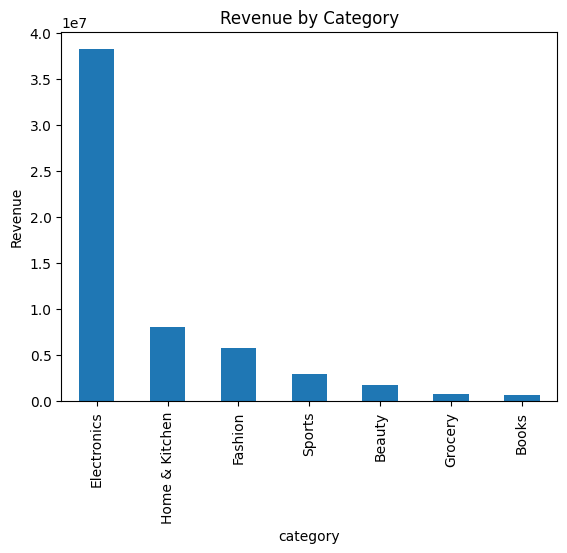

In [41]:
import matplotlib.pyplot as plt

cat = df.groupby("category")["order_amount"].sum().sort_values(ascending=False)
cat.plot(kind="bar")
plt.title("Revenue by Category")
plt.ylabel("Revenue")
plt.show()

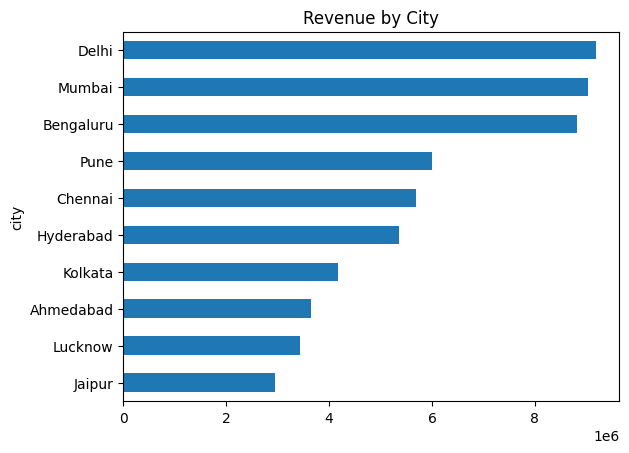

In [42]:
city = df.groupby("city")["order_amount"].sum().sort_values()
city.plot(kind="barh")
plt.title("Revenue by City")
plt.show()

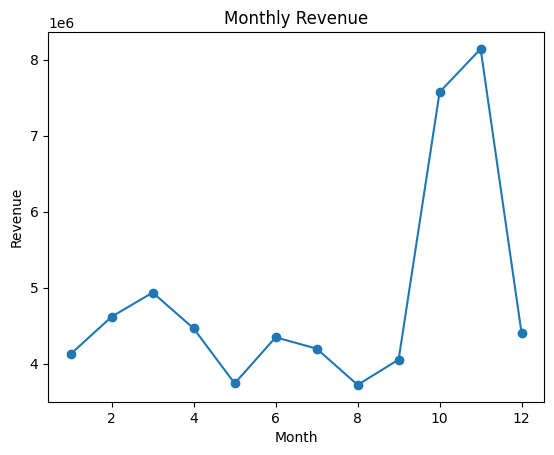

In [43]:
monthly = df.groupby("month")["order_amount"].sum()
monthly.plot(kind="line", marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

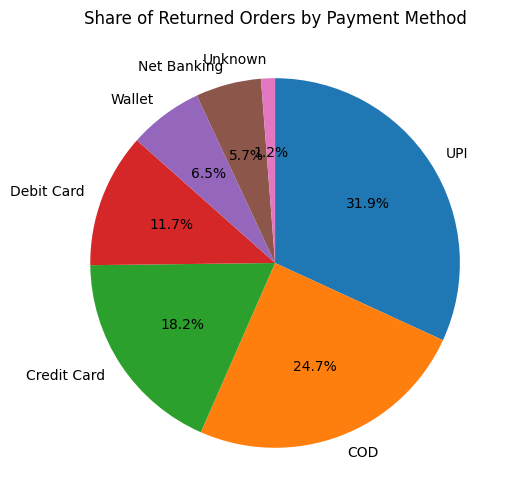

In [52]:
valid = ["UPI", "Credit Card", "Debit Card", "COD", "Net Banking", "Wallet"]
df["payment_method"] = df["payment_method"].where(df["payment_method"].isin(valid), "Unknown")

returned = df[df["is_returned"] == 1]["payment_method"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(returned, labels=returned.index, autopct="%1.1f%%", startangle=90, counterclock=False)
plt.title("Share of Returned Orders by Payment Method")
plt.show()

## 5. Insights

**Category:**  
Electronics generates about 66% of total revenue (₹3.8 crore of ₹5.7 crore), even though it has fewer orders than Fashion (1,831 vs 2,345). The reason is price: an average Electronics order is ₹20,660 versus ₹2,436 for Fashion. The business depends heavily on one category, so it should keep Electronics always in stock and also promote Home & Kitchen to reduce this dependence.

**Month:**  
Revenue almost doubles in October (₹75.6 lakh) and November (₹81.4 lakh) compared with a normal month (about ₹37-47 lakh), and orders rise from about 730 to over 1,250 per month. This is probably due to festive-season shopping (Diwali). The business should prepare stock and ads before October.

**City:**  
Delhi (₹91 lakh), Mumbai (₹89 lakh) and Bengaluru (₹86 lakh) are the top three cities by revenue. Bengaluru has the most orders (1,607), but Delhi earns more, so Delhi customers spend more per order. The business should run premium offers in Delhi and volume-based offers in Bengaluru.

**Returns:**  
The overall return rate is about 10.7%. Fashion has the highest category return rate (20%) versus 7-8% for most other categories, and COD orders are returned 15% of the time versus about 9% for UPI. Return rate also rises with discount: 9% at no discount versus 15% at 40% off. The business should improve size guides for Fashion and add confirmation for COD orders.

## 6. Conclusion & next steps
Electronics and the festive season drive revenue, while returns are concentrated in Fashion, COD orders and heavily discounted orders. Next, I will build a machine learning model to predict which orders will be returned.